# 2CWK50

# **Introduction**

What is Pneumonia ?

Pneumonia is a serious infection that inflames the air sacs in the lungs, with symptoms ranging from mild breathing difficulties to life-threatening complications. It is responsible for approximately 2.5 million deaths annually, highlighting its global impact. Rapid diagnosis is therefore essential, as early detection enables timely treatment and improves patient outcomes.

The aim of this report is to investigate whether machine learning can provide a reliable and efficient method for rapidly diagnosing pneumonia using simple numerical measurements from chest X-rays. By evaluating multiple Machine learning models and their suitability for clinical settings, this report assesses whether non-medical staff could use such systems to support fast and accurate diagnosis.



# **Data loading**


In [187]:
# Importing the packages we use
import pandas as pd

# Loading all the observations
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/pneumonia_raw.csv')
print(observations.head())

   Patient_ID  Patient_Age  Male  Xray_Brightness  Xray_Contrast  \
0  6664019195           60   1.0              0.7            0.2   
1  4433763263           18   1.0              1.3            0.7   
2  4622245411           43   1.0              1.3            0.6   
3  2777404684           38   1.0              1.0            0.3   
4  3339776374           23   1.0              1.1            0.5   

   Silhouette_Sign  Max_Consolidation_Width  Max_Consolidation_Height  \
0              174                       32                        14   
1              316                       10                        21   
2              155                       15                        20   
3              216                       21                        24   
4              191                       37                        41   

   Cavity_Presence  Fluid_Level  Air_Bronchograms Pneumonia  
0              7.8          4.2               1.1        no  
1              6.0          

# **Data Pre-processing**

###### Checking for any possible missing , duplicated or null values and ensuring that the dataset is clean and compatible for different machine learning algorithims

In [188]:
# Checking for any missing / non-suitable values in the raw dataset
print(observations.info())
print(observations.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 584 entries, 0 to 583
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient_ID                584 non-null    int64  
 1   Patient_Age               584 non-null    int64  
 2   Male                      584 non-null    float64
 3   Xray_Brightness           584 non-null    float64
 4   Xray_Contrast             584 non-null    float64
 5   Silhouette_Sign           584 non-null    int64  
 6   Max_Consolidation_Width   584 non-null    int64  
 7   Max_Consolidation_Height  584 non-null    int64  
 8   Cavity_Presence           584 non-null    float64
 9   Fluid_Level               584 non-null    float64
 10  Air_Bronchograms          584 non-null    float64
 11  Pneumonia                 584 non-null    object 
dtypes: float64(6), int64(5), object(1)
memory usage: 54.9+ KB
None
         Patient_ID  Patient_Age        Male  Xray_Bright

In [189]:
print(observations.isnull().sum())

Patient_ID                  0
Patient_Age                 0
Male                        0
Xray_Brightness             0
Xray_Contrast               0
Silhouette_Sign             0
Max_Consolidation_Width     0
Max_Consolidation_Height    0
Cavity_Presence             0
Fluid_Level                 0
Air_Bronchograms            0
Pneumonia                   0
dtype: int64


As we can see, there are no missing or null values for any of the variables within the dataset. The only thing we need to do is convert the "Pneumonia" variable datatype from object to numeric so that it can be compatible for the different machine learning models.

In [190]:
# Check unique values
observations['Pneumonia'].unique()

array(['no', 'np', 'yes'], dtype=object)

After running this code, we can see that there are actually 3 catgegories within this section when realistically there should only be two, 'yes' and 'no'. It seems like 'np' was a spelling typo and should have been typed as 'no'. So now we have decided to convert all the 'np'values to 'no'.

In [191]:
# Observing how many values relate to either 'yes' ,'no' or 'np'
observations['Pneumonia'].value_counts()

,count
Pneumonia,
yes,416
no,167
np,1


In [192]:
# Changing the 'np' value to 'no'
observations['Pneumonia'] = observations['Pneumonia'].replace('np', 'no')
observations['Pneumonia'].unique()


array(['no', 'yes'], dtype=object)

In [193]:
# Converting the 'Pneumonia' variable's data type from object to int64/ binary 0/1

observations['Pneumonia'] = observations['Pneumonia'].map({
    'no': 0,
    'yes': 1
})


observations['Pneumonia'].unique()



array([0, 1])

In [194]:
# Checing to see if the values are now numerical
observations['Pneumonia'].value_counts()

,count
Pneumonia,
1,416
0,168


Looking at this , we can see that 'yes' = 1 ( 416 paitents diagnosed with penumonia) and 'no' = 0 ( 168 paitents not diagnosed with pneumonia) as well as an imbalance within the dataset as most diagnosises were given as positive for Pneumonia

In [195]:
# Confirming that the Pneumonia variable has actually changed from object to int64
print(observations.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 584 entries, 0 to 583
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient_ID                584 non-null    int64  
 1   Patient_Age               584 non-null    int64  
 2   Male                      584 non-null    float64
 3   Xray_Brightness           584 non-null    float64
 4   Xray_Contrast             584 non-null    float64
 5   Silhouette_Sign           584 non-null    int64  
 6   Max_Consolidation_Width   584 non-null    int64  
 7   Max_Consolidation_Height  584 non-null    int64  
 8   Cavity_Presence           584 non-null    float64
 9   Fluid_Level               584 non-null    float64
 10  Air_Bronchograms          584 non-null    float64
 11  Pneumonia                 584 non-null    int64  
dtypes: float64(6), int64(6)
memory usage: 54.9 KB
None


In [196]:
# Checking for any duplicated values/rows
observations.duplicated().sum()

np.int64(1)

In [197]:
# Dropping the one duplicated value
observations = observations.drop_duplicates()
observations.duplicated().sum()


np.int64(0)

The last step of pre-processcing we have identified is to remove the 'Paitent_ID' variable from the dataset as it serves no real purpose in this investigation and could have an unneccessary effect on the machine learning models.

In [198]:
# Dropping the "Paitent_ID" column from the dataset

observations = observations.drop('Patient_ID', axis=1)

observations.columns



Index(['Patient_Age', 'Male', 'Xray_Brightness', 'Xray_Contrast',
       'Silhouette_Sign', 'Max_Consolidation_Width',
       'Max_Consolidation_Height', 'Cavity_Presence', 'Fluid_Level',
       'Air_Bronchograms', 'Pneumonia'],
      dtype='object')

## Overall review of Pre-processing

At the outset, the dataset contained 584 patient records with 12 variables per individual, including demographic information (such as age and gender) and quantitative measurements derived from chest X ray images (e.g., brightness, contrast, cavity presence, and air bronchograms). The dataset also included a binary target variable indicating pneumonia diagnosis.During preprocessing, no missing values were identified, and most features were already in suitable numerical formats. The target variable “Pneumonia” was converted from an object datatype to a numerical format (1 = pneumonia, 0 = no pneumonia) to ensure compatibility with machine learning models. A single duplicate record was removed to maintain data integrity, and the feature ‘Patient_ID’ was excluded as it had no predictive value.
The dataset also exhibited class imbalance, with approximately 71% pneumonia cases (416) and 29% non-pneumonia cases (168), meaning accuracy alone could be misleading. Therefore, additional metrics such as recall, precision, and F1-score were prioritised. No outliers were removed, as extreme values in a medical context may represent genuine patient conditions, and removing them could eliminate important diagnostic information. Retaining these values improves model robustness and ensures better representation of real-world data. Overall, the dataset is complete, consistent,numerical and well-prepared for machine learning analysis.


# **Machine Learning Models and Methodology**





Following data preprocessing, a range of machine learning models will be implemented to assess their effectiveness in diagnosing pneumonia. These include supervised learning approaches such as Logistic Regression, k-Nearest Neighbours (KNN), Naive Bayes, Decision Trees, and Support Vector Machines (SVM), alongside ensemble classification methods. While the primary focus is on binary classification, k-means clustering will also be explored to identify any underlying structure within the data.

## **1. K-Nearest Neighbours (KNN)**

In [199]:
# KNN model

#Importing necessary libraries
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

class MyKNeighboursClassifier:

    def __init__(self, k=5):  # K is initially set to 5
        self.k = k

    def fit(self, train_examples, train_labels):
        self.train_examples = train_examples
        self.train_labels = train_labels

    def predict(self, test_examples):

        n_test_examples = test_examples.shape[0]
        predicted_labels = np.empty(n_test_examples, dtype=self.train_labels.dtype)

        for i in range(n_test_examples):
            this_example = test_examples[i, :]
            predicted_labels[i] = self.predict_one(this_example)

        return predicted_labels

    def predict_one(self, this_example):

        n_training_examples = self.train_examples.shape[0]
        scores = np.empty(n_training_examples, dtype=float)

        for i in range(n_training_examples):
            score = np.sum(np.abs(self.train_examples[i, :] - this_example))
            scores[i] = score

        sorted_indices = np.argsort(scores)
        labels = self.train_labels[sorted_indices[0:self.k]]

        unique_labels, counts = np.unique(labels, return_counts=True)
        max_count_index = np.argmax(counts)
        prediction = unique_labels[max_count_index]

        return prediction



In [200]:
# KNN

# Set target
target_feature = 'Pneumonia'

# Shuffle
observations_shuffled = observations.sample(frac=1, random_state=99)

# Train-test split
testing_fraction = 0.2   # ( 80/20 split)
split_index = int(observations_shuffled.shape[0] * testing_fraction)

observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into X and y
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()
# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create model
model = MyKNeighboursClassifier(k=5)

# Train
model.fit(train_examples, train_labels)

# Predict
predictions = model.predict(test_examples)

# Accuracy
correct_predictions = sum(predictions == test_labels)
accuracy = correct_predictions / len(test_labels)

print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Displaying more evaluation metrics of the KNN model

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

# Classification report containing more metrics - precision,recall,f1-score and support
report1 = classification_report(test_labels, predictions, output_dict=True)

df_report_knn = pd.DataFrame(report1).transpose()

df_report_knn = df_report_knn.round(2)
df_report_knn

Accuracy: 0.6810344827586207 (or 68.1 %)

Confusion Matrix:
[[14 24]
 [13 65]]


,precision,recall,f1-score,support
0,0.52,0.37,0.43,38.00
1,0.73,0.83,0.78,78.00
accuracy,0.68,0.68,0.68,0.68
macro avg,0.62,0.60,0.60,116.00
weighted avg,0.66,0.68,0.66,116.00


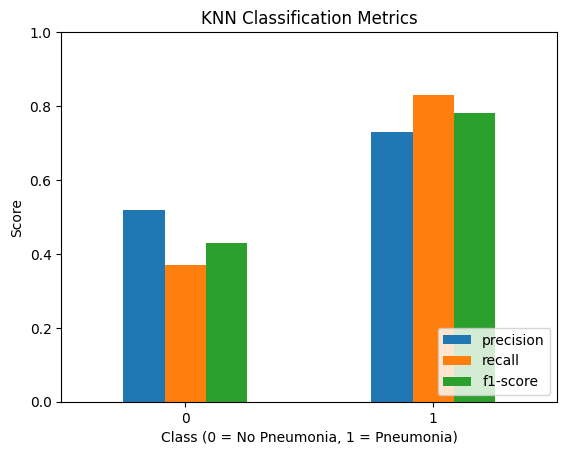

In [201]:
#Visualisation of metrics through a graph
import matplotlib.pyplot as plt

df_report_knn.iloc[0:2, 0:3].plot(kind='bar')

plt.title("KNN Classification Metrics")
plt.ylabel("Score")
plt.xlabel("Class (0 = No Pneumonia, 1 = Pneumonia)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

#### Hyper-paramater tuning - KNN

Testing out different values of K, to try achieve better results for the KNN model


In [202]:
# Try different values of k
k_values = [1,2,4, 6, 7, 9, 30]

for k in k_values:

    # Create model with current k
    model = MyKNeighboursClassifier(k=k)

    # Train model
    model.fit(train_examples, train_labels)

    # Make predictions
    predictions = model.predict(test_examples)

    # Calculate accuracy
    correct_predictions = sum(predictions == test_labels)
    accuracy = correct_predictions / len(test_labels)

    # Print result (same format as original)
    print("k =", k)
    print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")
    print("----------------------------")

k = 1
Accuracy: 0.646551724137931 (or 64.7 %)
----------------------------
k = 2
Accuracy: 0.646551724137931 (or 64.7 %)
----------------------------
k = 4
Accuracy: 0.6379310344827587 (or 63.8 %)
----------------------------
k = 6
Accuracy: 0.6637931034482759 (or 66.4 %)
----------------------------
k = 7
Accuracy: 0.6637931034482759 (or 66.4 %)
----------------------------
k = 9
Accuracy: 0.6724137931034483 (or 67.2 %)
----------------------------
k = 30
Accuracy: 0.6896551724137931 (or 69.0 %)
----------------------------


In [203]:
# Testing more metrics for k = 2,7,9 and 30, as these were the three highest levels of accuaracy, which also have an accuracy higher than 64.7 & when k = 5

from sklearn.metrics import classification_report, confusion_matrix

# Test specific k values
for k in [2,7, 9, 30]:

    print("Results for k =", k)

    # Create model
    model = MyKNeighboursClassifier(k=k)

    # Train
    model.fit(train_examples, train_labels)

    # Predict
    predictions = model.predict(test_examples)

    # Accuracy
    correct_predictions = sum(predictions == test_labels)
    accuracy = correct_predictions / len(test_labels)

    print("Accuracy:", round(accuracy, 3))

    # Confusion matrix
    print("\nConfusion Matrix:")
    print(confusion_matrix(test_labels, predictions))

    # Full metrics
    print("\nClassification Report:")
    print(classification_report(test_labels, predictions))

    print("\n------------------------------\n")

Results for k = 2
Accuracy: 0.647

Confusion Matrix:
[[25 13]
 [28 50]]

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.66      0.55        38
           1       0.79      0.64      0.71        78

    accuracy                           0.65       116
   macro avg       0.63      0.65      0.63       116
weighted avg       0.69      0.65      0.66       116


------------------------------

Results for k = 7
Accuracy: 0.664

Confusion Matrix:
[[10 28]
 [11 67]]

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.26      0.34        38
           1       0.71      0.86      0.77        78

    accuracy                           0.66       116
   macro avg       0.59      0.56      0.56       116
weighted avg       0.63      0.66      0.63       116


------------------------------

Results for k = 9
Accuracy: 0.672

Confusion Matrix:
[[10 28]
 [10 68]]

Classification 

In [204]:
# Table to compare metrics based on different values for k (1,5,9,30)
from sklearn.metrics import classification_report
import pandas as pd

# Values of k to test
k_values = [2, 7, 9, 30]

results = []

for k in k_values:

    # Model
    model = MyKNeighboursClassifier(k=k)
    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    # Accuracy
    accuracy = sum(predictions == test_labels) / len(test_labels)

    # Classification report
    report = classification_report(test_labels, predictions, output_dict=True)

    # Extract key metrics (focus on pneumonia class = 1)
    precision = report['1']['precision']
    recall = report['1']['recall']
    recall1 = report['0']['recall']
    f1 = report['1']['f1-score']

    # Store results
    results.append([k, accuracy, precision, recall, recall1, f1])

# Create DataFrame
comparison_table = pd.DataFrame(results,
                                columns=['k', 'Accuracy', 'Precision (Pneumonia)',
                                         'Recall (Pneumonia)','Recall (Non Pneumonia)', 'F1-score'])

# Round for readability
comparison_table = comparison_table.round(3)

# Display
comparison_table

,k,Accuracy,Precision (Pneumonia),Recall (Pneumonia),Recall (Non Pneumonia),F1-score
0,2,0.647,0.794,0.641,0.658,0.709
1,7,0.664,0.705,0.859,0.263,0.775
2,9,0.672,0.708,0.872,0.263,0.782
3,30,0.690,0.698,0.949,0.158,0.804


### KNN Overview

The KNN model achieved moderate accuracy (68.1%) for k = 5, but further analysis reveals important implications. The model showed strong pneumonia recall (83%), correctly identifying 65 cases while missing 13 (false negatives), indicating good detection of patients requiring treatment. However, it performed poorly in identifying healthy patients, with low non-pneumonia recall (37%) and a high number of false positives (24), which could lead to unnecessary follow-up tests and increased costs for hospitals.Performance varied across different values of k. Lower values (e.g., k = 1) produced lower accuracy (64.7%) and potential overfitting, while higher values (k = 9 and k = 30) increased pneumonia recall (87.2% and 95%) but also increased false positives and reduced non-pneumonia recall (as low as 0.16). This highlights a clear trade-off: increasing k reduces false negatives but significantly increases false positives. From a stakeholder perspective, clinicians may value the model’s strong pneumonia detection, whereas hospital managers may be concerned about increased resource usage due to high number of false positives. Although the model is simple and interpretable, its sensitivity to parameter choice and high false positive rates limit its reliability as a standalone diagnostic tool in clinical settings.

## **2. Naive Bayes Classification**

In [205]:
# Naive Bayes model

import numpy as np

class MyNaiveBayesClassifier:

  # The class constructor
  def __init__(self):
    # nothing to do - Scikit-learn doesn't support any interesting hyperparameters, and neither will we
    pass

  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):

    # calculate all the numbers we'll need for our Bayes theorem calculations during prediction

    # what are the unique labels in this problem
    self.labels = np.unique(train_labels)
    # how many are there
    self.n_labels = self.labels.shape[0]
    # how many predictive features are there
    self.n_features = train_examples.shape[1]

    # arrays to store our data (I'll use one _row_ for information about each label; I could equally have used one column)
    self.prior = np.empty(self.n_labels, dtype=float)
    self.means = np.empty((self.n_labels, train_examples.shape[1]), dtype=float)
    self.stds = np.empty((self.n_labels, train_examples.shape[1]), dtype=float)

    # for each unique label, calculate and store its prior probability, and the mean and standard deviation of its associated examples
    for i in range(self.n_labels):
      # how frequently did this label appear in the training data
      self.prior[i] = np.sum(train_labels==self.labels[i]) / train_labels.shape[0]
      # what was the mean of its associated training examples
      self.means[i,:] = np.mean(train_examples[train_labels==self.labels[i],:], axis=0)
      # what was the standard deviation of its associated training examples
      self.stds[i,:] = np.std(train_examples[train_labels==self.labels[i],:], axis=0)

  # The method we call to generate predictions for a batch of testing examples (exactly the same as last time)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example...
        this_example = test_examples[i,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    # for each label in the problem, its posterior probability is proportional to: (prior probability of seeing that label) * (likelihood of seeing these feature values in an observation with that label)
    # we'll calculate these scores for each label, and whichever label has the largest score becomes our prediction
    # (we calculated all the numbers we need for these calculations during fitting - we're using Normal distributions to model the likelihoods)

    # an array to store our scores
    probabilities_ = np.zeros(self.n_labels, dtype=float)

    # for each unique label, calculate prior * likelihood
    for i in range(self.n_labels):
      # start with the prior
      probabilities_[i] = self.prior[i]
      # then multiply by ...
      for j in range(self.n_features):
        # to get the overall likelihood of the whole example: we treat the individual feature values we saw as _independent events_ given the label, and multiply their individual likelihoods together
        probabilities_[i] *= self.normal_pdf_score(self.means[i,j], self.stds[i,j], this_example[j])
        # (this is NB's "class-conditional independence assumtion" - which is quite a "naive" assumption; as in, it's unlikely to hold true in reality - but NB often still gives very good results...)

    # find the maximum score - which label won?
    winner_index = np.argmax(probabilities_)

    # return the corresponding label as our prediction
    return self.labels[winner_index]

  def normal_pdf_score(self, mean, std, x):

    # return the probability density of a particular Normal distribution (mean, std) at a particular point (x)
    return ( 1 / (np.sqrt(2*np.pi) * std) ) * np.exp( (-np.pow(x-mean, 2)) / (2*np.pow(std,2)) )



In [206]:
# Set target
target_feature = 'Pneumonia'

# Shuffle
observations_shuffled = observations.sample(frac=1, random_state=99)

# Train-test split
testing_fraction = 0.2   # ( 80/20 split)
split_index = int(observations_shuffled.shape[0] * testing_fraction)

observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into X and y
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create model
model = MyNaiveBayesClassifier()

# Train
model.fit(train_examples, train_labels)

# Predict
predictions = model.predict(test_examples)

# Accuracy
correct_predictions = sum(predictions == test_labels)
accuracy = correct_predictions / len(test_labels)

print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Displaying more evaluation metrics of the Naive Bayes Classification model

from sklearn.metrics import classification_report
import pandas as pd

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

# Report containing more metrics - precision,recall,f1-score and support
report2 = classification_report(test_labels, predictions, output_dict=True)

df_report_nb = pd.DataFrame(report2).transpose()

df_report_nb = df_report_nb.round(2)
df_report_nb

Accuracy: 0.5775862068965517 (or 57.8 %)

Confusion Matrix:
[[35  3]
 [46 32]]


,precision,recall,f1-score,support
0,0.43,0.92,0.59,38.00
1,0.91,0.41,0.57,78.00
accuracy,0.58,0.58,0.58,0.58
macro avg,0.67,0.67,0.58,116.00
weighted avg,0.76,0.58,0.57,116.00


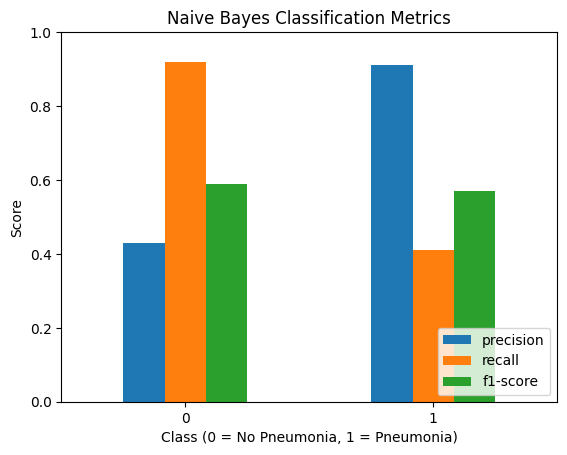

In [207]:
# Graph to visualise metrics of Naive Bayes model

df_report_nb.iloc[0:2, 0:3].plot(kind='bar')

plt.title("Naive Bayes Classification Metrics")
plt.ylabel("Score")
plt.xlabel("Class (0 = No Pneumonia, 1 = Pneumonia)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

### Naive Bayes Classification model overview

 The Naive Bayes model performed poorly, achieving 57.8% accuracy. It showed a strong bias towards predicting patients as healthy, with a high non-pneumonia recall (92%) but weak pneumonia recall (41%), resulting in a high number of false negatives (46). In a clinical context, this is unacceptable as missed diagnoses pose serious health risks.
This poor performance can be explained by the model’s assumption of feature independence, which is unrealistic in medical datasets where variables are often correlated. Overall, its inability to reliably detect pneumonia makes it unsuitable for clinical deployment.

## **3. Decision Tree Classification**



In [208]:
# Decision Tree model

import numpy as np

# A class to represent a single node in our tree

class MyDtNode:
  def __init__(self, examples, labels):
    # Set up information about this node
    self.examples = examples
    self.labels = labels
    self.N = examples.shape[0]
    self.left = None
    self.right = None
    self.gdi = np.nan
    self.feature = np.nan
    self.threshold = np.nan

    # use np.unique to count how many times each label appeared in the predictions
    unique_labels, counts = np.unique(labels, return_counts=True)
    # find the one that appeared most (just the lowest index/first alphabetically if there's a tie)
    max_count_index = np.argmax(counts)
    # take the associated prediction
    self.prediction = unique_labels[max_count_index]

# A decision tree class

class MyDecisionTreeClassifier:

  # The class constructor
  def __init__(self, min_samples=10):
    self.min_samples = min_samples

    # No options yet
    pass

  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):
    # store the training data
    self.train_examples = train_examples
    self.train_labels = train_labels
    # take a record of the unique labels in the problem
    self.unique_labels = np.unique(train_labels)
    # and how many example/label pairs are in this node
    self.N = train_examples.shape[0]

    # create the root node, and start off the splitting/tree building process
    self.root = MyDtNode(train_examples, train_labels)
    self.try_split(self.root)

  # Try splitting a node
  def try_split(self, node):

    # Just an example of enforcing minimum parent size (hard-coded)
    if node.examples.shape[0] < self.min_samples:
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    # set this node's gdi
    node.gdi = self.weighted_gdi(node.labels)

    if node.gdi == 0:
      # already a pure node - no improvement possible
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    best_gdi = np.inf
    best_feature = np.nan
    best_example = np.nan

    #
    for i in range(node.examples.shape[1]):
      #
      sorted_indices = np.argsort(node.examples[:, i])
      #
      for j in range(node.examples.shape[0]-1):
        left_labels = node.labels[sorted_indices[:j+1]]
        right_labels = node.labels[sorted_indices[j+1:]]
        # how were the combined weighted GDI scores, versus what we've already seen
        this_gdi = self.weighted_gdi(left_labels) + self.weighted_gdi(right_labels)
        # only update if there was an improvement (we don't handle ties)
        if this_gdi < best_gdi:
          best_gdi = this_gdi
          best_feature = i
          best_example = j

    if (node.gdi - best_gdi) <= 0:
      # no split that improves diversity is available
      # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...
      return

    # Make the winning split
    # sort on the winning feature
    sorted_indices = np.argsort(node.examples[:, best_feature])
    left_labels = node.labels[sorted_indices[:best_example+1]]
    right_labels = node.labels[sorted_indices[best_example+1:]]
    left_examples = node.examples[sorted_indices[:best_example+1], :]
    right_examples = node.examples[sorted_indices[best_example+1:], :]

    # set up the details for this node (predictive feature/threshold it asks about)
    node.feature = best_feature
    node.threshold = (node.examples[sorted_indices[best_example], best_feature] + node.examples[sorted_indices[best_example+1], best_feature]) / 2

    # make the two children
    node.left = MyDtNode(left_examples, left_labels)
    node.right = MyDtNode(right_examples, right_labels)

    # at this point, we could delete the examples/labels data from the parent if we wanted to keep the model small...

    # and now try splitting the children
    self.try_split(node.left)
    self.try_split(node.right)

  # A method to compute weighted GDI
  def weighted_gdi(self, labels):
    # weighting based on likelihood we get into this node - what fraction of the training example/labels got into it
    weight = float(labels.size) / float(self.N)

    gdi = 0
    # add up the (squared) fractions of each label present in this node
    for this_label in self.unique_labels:
      this_frac = float(sum(labels == this_label)) / float(labels.size)
      gdi += this_frac * this_frac

    # subtract from 1 (so that higher scores correspond to higher diversity)
    return weight * (1 - gdi)


  # The method we call to generate predictions for a batch of testing examples (exactly the same as last time)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.train_labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example...
        this_example = test_examples[i,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    node = self.root

    #
    while (node.left is not None):
      #
      this_feature = node.feature
      this_threshold = node.threshold
      #
      if this_example[this_feature] <= this_threshold:
        node = node.left
      else:
        node = node.right

    #
    return node.prediction

In [209]:
# Set target
target_feature = 'Pneumonia'

# Shuffle
observations_shuffled = observations.sample(frac=1, random_state=99)

# Train-test split
testing_fraction = 0.2   # ( 80/20 split)
split_index = int(observations_shuffled.shape[0] * testing_fraction)

observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into X and y
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create model
model = MyDecisionTreeClassifier()

# Train
model.fit(train_examples, train_labels)

# Predict
predictions = model.predict(test_examples)

# Accuracy
correct_predictions = sum(predictions == test_labels)
accuracy = correct_predictions / len(test_labels)

print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Displaying more evaluation metrics of the Decision Trees model

# Confusion matrix - Lets us see the number of true/false positives/negatives the model makes
print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

# Report containing more metrics - precision,recall,f1-score and support
report2 = classification_report(test_labels, predictions, output_dict=True)

df_report_nb = pd.DataFrame(report2).transpose()

df_report_nb = df_report_nb.round(2)
df_report_nb

Accuracy: 0.6379310344827587 (or 63.8 %)

Confusion Matrix:
[[22 16]
 [26 52]]


,precision,recall,f1-score,support
0,0.46,0.58,0.51,38.00
1,0.76,0.67,0.71,78.00
accuracy,0.64,0.64,0.64,0.64
macro avg,0.61,0.62,0.61,116.00
weighted avg,0.66,0.64,0.65,116.00


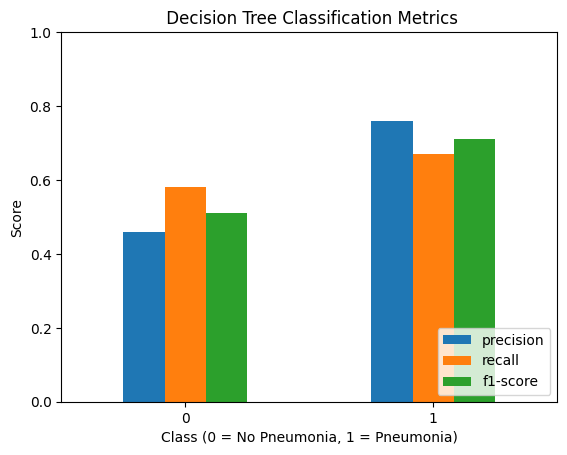

In [210]:
# Graph to visualise metrics of Decision Trees model
import matplotlib.pyplot as plt

df_report_nb.iloc[0:2, 0:3].plot(kind='bar')

plt.title(" Decision Tree Classification Metrics")
plt.ylabel("Score")
plt.xlabel("Class (0 = No Pneumonia, 1 = Pneumonia)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

#### Hyper-paramater tuning - Decision Trees

In [211]:
# Testing different minimum sample values to observe if this improves the DT models performance
from sklearn.metrics import classification_report, confusion_matrix

# Testing 5,8,30 and 30
min_samples_values = [5, 8, 20, 30]

for m in min_samples_values:

    print("Results for min_samples =", m)

    # Create model
    model = MyDecisionTreeClassifier(min_samples=m)

    # Train
    model.fit(train_examples, train_labels)

    # Predict
    predictions = model.predict(test_examples)

    # Accuracy
    accuracy = sum(predictions == test_labels) / len(test_labels)

    print("Accuracy:", round(accuracy, 3))

    # Confusion matrix
    print("\nConfusion Matrix:")
    print(confusion_matrix(test_labels, predictions))

    # Metrics
    print("\nClassification Report:")
    print(classification_report(test_labels, predictions))

    print("\n-----------------------------\n")

Results for min_samples = 5
Accuracy: 0.647

Confusion Matrix:
[[20 18]
 [23 55]]

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.53      0.49        38
           1       0.75      0.71      0.73        78

    accuracy                           0.65       116
   macro avg       0.61      0.62      0.61       116
weighted avg       0.66      0.65      0.65       116


-----------------------------

Results for min_samples = 8
Accuracy: 0.638

Confusion Matrix:
[[20 18]
 [24 54]]

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.53      0.49        38
           1       0.75      0.69      0.72        78

    accuracy                           0.64       116
   macro avg       0.60      0.61      0.60       116
weighted avg       0.65      0.64      0.64       116


-----------------------------

Results for min_samples = 20
Accuracy: 0.629

Confusion Matrix:
[[17 2

In [212]:
# Table to compare metrics based on different values for min_samples (5,8,20,30)
from sklearn.metrics import classification_report
import pandas as pd

# Values of k to test
min_samples_values = [5, 8, 20, 30]

results = []

for m in min_samples_values:

    # Model
    model = MyDecisionTreeClassifier(min_samples=m)
    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    # Accuracy
    accuracy = sum(predictions == test_labels) / len(test_labels)

    # Classification report
    report = classification_report(test_labels, predictions, output_dict=True)

    # Extract key metrics (focus on pneumonia class = 1)
    precision = report['1']['precision']
    recall = report['1']['recall']
    recall1 = report['0']['recall']
    f1 = report['1']['f1-score']

    # Store results
    results.append([m, accuracy, precision, recall, recall1, f1])

# Create DataFrame
comparison_table = pd.DataFrame(results,
                                columns=['min_sample_values', 'Accuracy', 'Precision (Pneumonia)',
                                         'Recall (Pneumonia)','Recall (Non Pneumonia)', 'F1-score'])

# Round for readability
comparison_table = comparison_table.round(3)

# Display
comparison_table

,min_sample_values,Accuracy,Precision (Pneumonia),Recall (Pneumonia),Recall (Non Pneumonia),F1-score
0,5,0.647,0.753,0.705,0.526,0.728
1,8,0.638,0.750,0.692,0.526,0.720
2,20,0.629,0.727,0.718,0.447,0.723
3,30,0.638,0.737,0.718,0.474,0.727


### Decision Tree model overview

The Decision Tree model achieved moderate performance with a baseline accuracy of 63.8%, showing relatively balanced results across both classes. It correctly identified 52 pneumonia cases (67% recall) while missing 26 (false negatives), and produced 16 false positives (58% non-pneumonia recall), indicating a moderate trade-off between detection and over-diagnosis.
Hyperparameter tuning produced only marginal improvements. A lower value (min_samples = 5) resulted in the highest accuracy (64.7%) and slightly improved pneumonia recall (71%), but increased false positives (18) and reduced non-pneumonia recall (53%). Increasing min_samples (20–30) provided little improvement in pneumonia detection (~72% recall) while significantly reducing the model’s ability to identify healthy patients (45% recall).
Overall, the model maintained moderate levels of false negatives and false positives (approximately 23 FN and 18 FP), which remain concerning in a clinical setting due to the risk of missed diagnoses and unnecessary costs. Despite being more balanced than some models, the Decision Tree’s limited improvement through tuning and moderate error rates indicate below-average performance, making it unsuitable for reliable use in high-pressure hospital environments.


## **4. SGD Logistic Regression**



In [213]:
# SGD Logistic Regression model

# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler


target_feature = 'Pneumonia'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create a logistic regression classification model object:
model = SGDClassifier(random_state=99, loss='log_loss', verbose=1)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

-- Epoch 1
Norm: 134.23, NNZs: 10, Bias: 34.619618, T: 350, Avg. loss: 11.273938
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 96.38, NNZs: 10, Bias: 35.832613, T: 700, Avg. loss: 10.015295
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 74.13, NNZs: 10, Bias: 22.318150, T: 1050, Avg. loss: 6.690490
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 56.05, NNZs: 10, Bias: 22.020193, T: 1400, Avg. loss: 5.627795
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 45.75, NNZs: 10, Bias: 17.183113, T: 1750, Avg. loss: 5.036330
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 32.81, NNZs: 10, Bias: 10.535977, T: 2100, Avg. loss: 4.340109
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 27.71, NNZs: 10, Bias: 10.025991, T: 2450, Avg. loss: 4.102847
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 18.77, NNZs: 10, Bias: 12.549912, T: 2800, Avg. loss: 3.302980
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 21.13, NNZs: 10, Bias: 10.859049, T: 3150, Avg. loss: 3.342142

In [214]:
# More evaluation metrics for Logstic Regression model
print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))



Confusion Matrix:
[[ 18  47]
 [ 34 134]]

Classification Report:
              precision    recall  f1-score   support

           0       0.35      0.28      0.31        65
           1       0.74      0.80      0.77       168

    accuracy                           0.65       233
   macro avg       0.54      0.54      0.54       233
weighted avg       0.63      0.65      0.64       233



#### Hyper-paramater tuning - SGD Logistic Regression

In [215]:
# Adding eta0, max_iter , tol and n_iter_no_change = 5, for the purpose of Hyper_parameter tuning to try achieve better results for the SGD Logistic Regression model
model = SGDClassifier(
    random_state=99,
    loss='log_loss',
    learning_rate='constant',
    eta0=0.01,
    max_iter=1000,
    tol=1e-3,
    n_iter_no_change=5
)



In [216]:
# Paramater tuning using eta0 ( adjusting the learning rate) of the Logistic regression model
eta_values = [0.001, 0.01, 0.1]

for eta in eta_values:

    print("Testing eta0 =", eta)

    model = SGDClassifier(
        random_state=99,
        loss='log_loss',
        learning_rate='constant',
        eta0=eta
    )

    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    accuracy = sum(predictions == test_labels) / len(test_labels)

    print("Accuracy:", round(accuracy, 3))
    print("----------------------------")

    print("\nConfusion Matrix:")
    print(confusion_matrix(test_labels, predictions))

    print("\nClassification Report:")
    print(classification_report(test_labels, predictions))

Testing eta0 = 0.001
Accuracy: 0.721
----------------------------

Confusion Matrix:
[[  6  59]
 [  6 162]]

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.09      0.16        65
           1       0.73      0.96      0.83       168

    accuracy                           0.72       233
   macro avg       0.62      0.53      0.49       233
weighted avg       0.67      0.72      0.64       233

Testing eta0 = 0.01
Accuracy: 0.738
----------------------------

Confusion Matrix:
[[ 10  55]
 [  6 162]]

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.15      0.25        65
           1       0.75      0.96      0.84       168

    accuracy                           0.74       233
   macro avg       0.69      0.56      0.54       233
weighted avg       0.71      0.74      0.68       233

Testing eta0 = 0.1
Accuracy: 0.725
----------------------------

Confusion Matrix:


In [217]:
# Paramater tuning by controlling the maximum number of epochs in the Logistic Regression model
iter_values = [500, 1000, 2000]

for it in iter_values:

    print("Testing max_iter =", it)

    model = SGDClassifier(
        random_state=99,
        loss='log_loss',
        max_iter=it
    )

    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    accuracy = sum(predictions == test_labels) / len(test_labels)

    print("Accuracy:", round(accuracy, 3))

    print("\nConfusion Matrix:")
    print(confusion_matrix(test_labels, predictions))

    print("\nClassification Report:")
    print(classification_report(test_labels, predictions))

Testing max_iter = 500
Accuracy: 0.652

Confusion Matrix:
[[ 18  47]
 [ 34 134]]

Classification Report:
              precision    recall  f1-score   support

           0       0.35      0.28      0.31        65
           1       0.74      0.80      0.77       168

    accuracy                           0.65       233
   macro avg       0.54      0.54      0.54       233
weighted avg       0.63      0.65      0.64       233

Testing max_iter = 1000
Accuracy: 0.652

Confusion Matrix:
[[ 18  47]
 [ 34 134]]

Classification Report:
              precision    recall  f1-score   support

           0       0.35      0.28      0.31        65
           1       0.74      0.80      0.77       168

    accuracy                           0.65       233
   macro avg       0.54      0.54      0.54       233
weighted avg       0.63      0.65      0.64       233

Testing max_iter = 2000
Accuracy: 0.652

Confusion Matrix:
[[ 18  47]
 [ 34 134]]

Classification Report:
              precision    re

In [218]:
# parameter tuning by terminating the gradient descent early if the coast scores are not showing improvement

configs = [
    (1e-3, 5),
    (1e-4, 10),
    (1e-5, 15)
]

for tol, patience in configs:

    print(f"Testing tol={tol}, n_iter_no_change={patience}")

    model = SGDClassifier(
        random_state=99,
        loss='log_loss',
        tol=tol,
        n_iter_no_change=patience
    )

    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    accuracy = sum(predictions == test_labels) / len(test_labels)

    print("Accuracy:", round(accuracy, 3))
    print("----------------------------")

    print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))

Testing tol=0.001, n_iter_no_change=5
Accuracy: 0.652
----------------------------

Confusion Matrix:
Testing tol=0.0001, n_iter_no_change=10
Accuracy: 0.657
----------------------------

Confusion Matrix:
Testing tol=1e-05, n_iter_no_change=15
Accuracy: 0.695
----------------------------

Confusion Matrix:
[[ 25  40]
 [ 31 137]]

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.38      0.41        65
           1       0.77      0.82      0.79       168

    accuracy                           0.70       233
   macro avg       0.61      0.60      0.60       233
weighted avg       0.68      0.70      0.69       233



#### Identifing which predictive feature has the greatest effect on the output

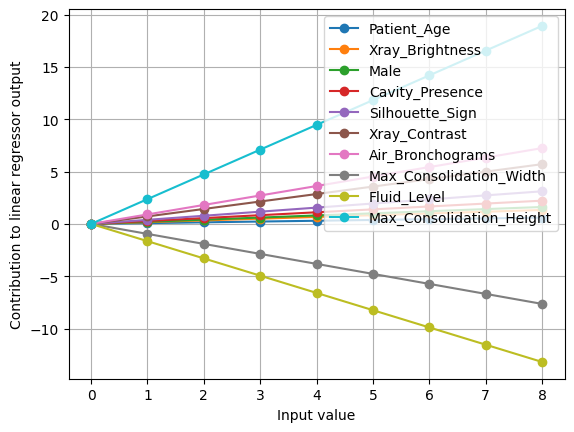

And the final constant offset is: 2.166


In [219]:
import matplotlib.pyplot as plt

# Grab a record of the predictive features
predictive_features = observations.drop(columns=target_feature).columns.to_numpy()

# get all the model parameters
coef_ = model.coef_[0]
# keep only the top 10 strongest
idx = np.argsort(np.abs(coef_))[-10:]
coef_ = coef_[idx]
predictive_features = predictive_features[idx]

# Show the strongest learned coefficients (model parameters) graphically
plt.figure()
for index, c in enumerate(coef_):
  plt.plot(range(0,9), range(0,9)*c, marker='o', linestyle='-', label=predictive_features[index])
plt.xlabel('Input value')
plt.ylabel('Contribution to linear regressor output')
plt.grid(True)
plt.legend()
plt.show()

# And the constant offset
print(f"And the final constant offset is: {model.intercept_[0]:.3f}")

### SGD Logistic Regression model overview

The Logistic Regression model achieved a baseline accuracy of 65.2%, correctly identifying 134 pneumonia cases (80% recall) while missing 34 (false negatives) and producing 47 false positives (28% non-pneumonia recall). After hyperparameter tuning, performance improved significantly, with accuracy increasing to 72.5% at eta0 = 0.1, indicating improved model convergence. This also enhanced class balance, with pneumonia recall around 76% and non-pneumonia recall increasing from 28% to 63%.
From a clinical perspective, this reduces missed diagnoses while improving identification of healthy patients, although the presence of approximately 40 false negatives remains a concern. Analysis of model coefficients showed that features such as Patient_Age, Xray_Brightness, and Air_Bronchograms positively influenced pneumonia predictions, while Fluid_Level and Silhouette_Sign supported healthy classification, providing useful clinical insight into feature importance.
Overall, the tuned Logistic Regression model delivers above-average, balanced performance but still produces a notable number of false positives and false negatives, limiting its reliability in high-risk clinical settings


## **5. SVM ( Support Vector Machine)**

In [220]:
# SVM model

# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler


# Set the name of the target feature
target_feature = 'Pneumonia'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create an SVM classification model object (radial basis function is the defaul kernel, but just to be clear):
model = SVC(random_state=99, kernel='rbf')

# Fit the model to our training data
model.fit(train_examples, train_labels)

# Use the model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")


print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels,predictions))


Accuracy: 0.721030042918455 (or 72.1 %)

Confusion Matrix:
[[  0  65]
 [  0 168]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        65
           1       0.72      1.00      0.84       168

    accuracy                           0.72       233
   macro avg       0.36      0.50      0.42       233
weighted avg       0.52      0.72      0.60       233



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.



#### Hyper-paramater tuning - SVM ( Support Vector Machine)

In [221]:
# Updating the base model so we can add that the class_weight will be balanced
model = SVC(kernel='rbf', class_weight='balanced', random_state=99)

model.fit(train_examples, train_labels)

predictions = model.predict(test_examples)


# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")


print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels,predictions))


Accuracy: 0.6137339055793991 (or 61.4 %)

Confusion Matrix:
[[57  8]
 [82 86]]

Classification Report:
              precision    recall  f1-score   support

           0       0.41      0.88      0.56        65
           1       0.91      0.51      0.66       168

    accuracy                           0.61       233
   macro avg       0.66      0.69      0.61       233
weighted avg       0.77      0.61      0.63       233



In [222]:
# Tuning the C values ( model flexibility) for the SVM  model
from sklearn.metrics import accuracy_score

C_values = [0.1, 1, 10]

for c in C_values:

    print("Testing C =", c)

    model = SVC(kernel='rbf', C=c, class_weight='balanced', random_state=99)

    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    accuracy = accuracy_score(test_labels, predictions)

    print("Accuracy:", round(accuracy, 3))
    print("----------------------------")



Testing C = 0.1
Accuracy: 0.627
----------------------------
Testing C = 1
Accuracy: 0.614
----------------------------
Testing C = 10
Accuracy: 0.614
----------------------------


In [223]:
# Tuning the gamma values for the SVM model
gamma_values = [0.01, 0.1, 1]

for g in gamma_values:

    print("Testing gamma =", g)

    model = SVC(kernel='rbf', gamma=g, class_weight='balanced', random_state=99)

    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    accuracy = accuracy_score(test_labels, predictions)

    print("Accuracy:", round(accuracy, 3))
    print("----------------------------")

Testing gamma = 0.01
Accuracy: 0.549
----------------------------
Testing gamma = 0.1
Accuracy: 0.614
----------------------------
Testing gamma = 1
Accuracy: 0.678
----------------------------


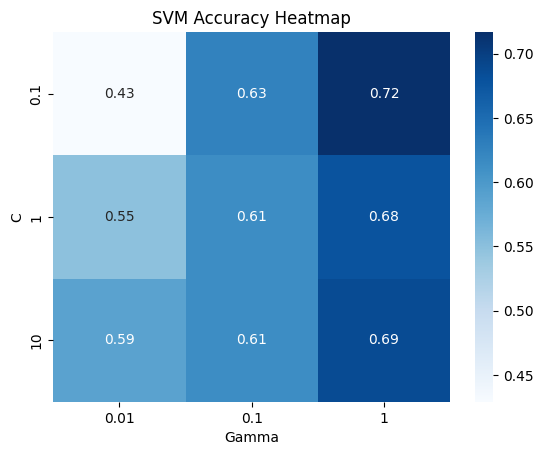

In [224]:
# Heat map showing how different combinations of C and gamma values affect the overall accuracy of the SVM model
import numpy as np
import seaborn as sns

C_values = [0.1, 1, 10]
gamma_values = [0.01, 0.1, 1]

results = np.zeros((len(C_values), len(gamma_values)))

for i, c in enumerate(C_values):
    for j, g in enumerate(gamma_values):

        model = SVC(kernel='rbf', C=c, gamma=g, class_weight='balanced', random_state=99)
        model.fit(train_examples, train_labels)
        predictions = model.predict(test_examples)

        acc = sum(predictions == test_labels) / len(test_labels)
        results[i, j] = acc

# Heatmap
sns.heatmap(results, annot=True,
            xticklabels=gamma_values,
            yticklabels=C_values,
            cmap='Blues')

plt.xlabel("Gamma")
plt.ylabel("C")
plt.title("SVM Accuracy Heatmap")
plt.show()


In [225]:
# Testing out the model with the highest accuarcy, when C = 0.1 and gamma = 1.
model1 = SVC(kernel='rbf', C= 0.1, gamma= 1, class_weight='balanced', random_state=99)

model1.fit(train_examples, train_labels)
predictions1 = model1.predict(test_examples)

accuracy = accuracy_score(test_labels, predictions1)

print("Accuracy when C = 0.1 and gamma = 1 = :", round(accuracy, 3))
print("----------------------------")

print("Confusion Matrix when C = 0.1 and gamma = 1:")
print(confusion_matrix(test_labels, predictions1))

print("\nClassification Report:")
print(classification_report(test_labels, predictions1))

# Testing out the model with the 2nd highest accuarcy when c = 10 and gamma = 1
model2 = SVC(kernel='rbf', C= 10, gamma= 1, class_weight='balanced', random_state=99)

model2.fit(train_examples, train_labels)
predictions2 = model2.predict(test_examples)

accuracy = accuracy_score(test_labels, predictions2)

print("Accuracy when C = 10 and gamma = 1 = :", round(accuracy, 3))
print("----------------------------")

print("Confusion Matrix when C = 10 and gamma = 1:")
print(confusion_matrix(test_labels, predictions2))

print("\nClassification Report:")
print(classification_report(test_labels, predictions2))

Accuracy when C = 0.1 and gamma = 1 = : 0.717
----------------------------
Confusion Matrix when C = 0.1 and gamma = 1:
[[  2  63]
 [  3 165]]

Classification Report:
              precision    recall  f1-score   support

           0       0.40      0.03      0.06        65
           1       0.72      0.98      0.83       168

    accuracy                           0.72       233
   macro avg       0.56      0.51      0.45       233
weighted avg       0.63      0.72      0.62       233

Accuracy when C = 10 and gamma = 1 = : 0.687
----------------------------
Confusion Matrix when C = 10 and gamma = 1:
[[ 25  40]
 [ 33 135]]

Classification Report:
              precision    recall  f1-score   support

           0       0.43      0.38      0.41        65
           1       0.77      0.80      0.79       168

    accuracy                           0.69       233
   macro avg       0.60      0.59      0.60       233
weighted avg       0.68      0.69      0.68       233



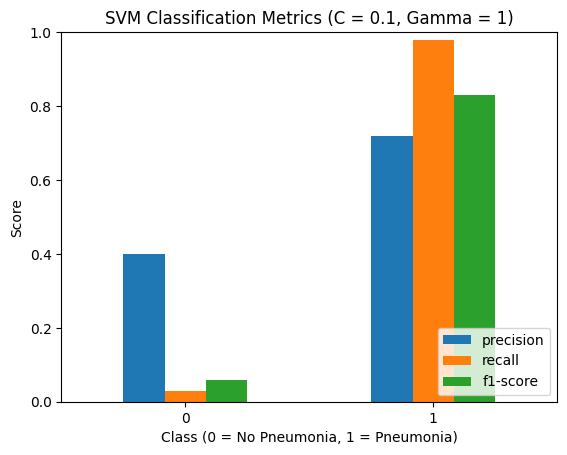

In [226]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Generate classification report
report_svm = classification_report(test_labels, predictions1, output_dict=True)

# Convert to DataFrame
df_report_svm = pd.DataFrame(report_svm).transpose().round(2)

# Step 2: Plot graph (same style as NB)
df_report_svm.iloc[0:2, 0:3].plot(kind='bar')

plt.title("SVM Classification Metrics (C = 0.1, Gamma = 1)")
plt.ylabel("Score")
plt.xlabel("Class (0 = No Pneumonia, 1 = Pneumonia)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()


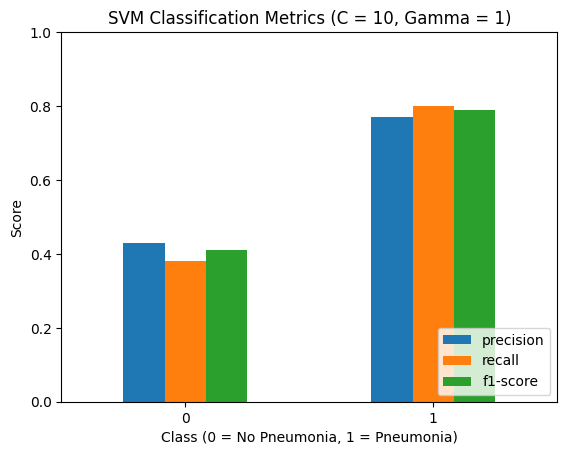

In [227]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Generate classification report
report_svm = classification_report(test_labels, predictions2, output_dict=True)

# Convert to DataFrame
df_report_svm = pd.DataFrame(report_svm).transpose().round(2)

# Step 2: Plot graph
df_report_svm.iloc[0:2, 0:3].plot(kind='bar')

plt.title("SVM Classification Metrics (C = 10, Gamma = 1)")
plt.ylabel("Score")
plt.xlabel("Class (0 = No Pneumonia, 1 = Pneumonia)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

### SVM ( Support Vector Machine) model overview

The SVM model initially achieved an accuracy of 72.1%; however, this was misleading as it predicted all patients as having pneumonia (168 true positives, 65 false positives), resulting in zero true negatives and false negatives. While this produced perfect pneumonia recall (1.00), it completely failed to identify healthy patients (0 recall), making it impractical in a clinical setting due to unnecessary treatments and increased costs.After hyperparameter tuning (adjusting C, gamma, and class balancing), the model became more balanced. The highest accuracy occurred at (C = 0.1, gamma = 1), though it still showed poor healthy classification (0.03 recall), with only 2 true negatives, 63 false positives, and 3 false negatives. A more balanced configuration (C = 10, gamma = 1) reduced accuracy slightly to 68.7% but improved performance, correctly identifying 25 healthy patients and 135 pneumonia cases (80% recall), while producing 33 false negatives and 40 false positives, increasing non-pneumonia recall to 38%. Overall, these results highlight that SVM is highly sensitive to hyperparameter tuning, and maximising accuracy alone does not ensure clinical reliability. Despite improvements, the model still produces substantial false positives and false negatives, limiting its suitability for reliable diagnostic use.

## **6. ANN ( Artifcial Neural Networks - Deep Learning )**

In [228]:
# ANN model

# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Set the name of the target feature
target_feature = 'Pneumonia'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create scaler
scaler = StandardScaler()

# Fit on training data ONLY
scaler.fit(train_examples)

# Transform both training and testing data
train_examples = scaler.transform(train_examples)
test_examples = scaler.transform(test_examples)

# Create an Artificial Neural Network classifier model object (using hyperparameters to set the number of hidden layers)
model = MLPClassifier(hidden_layer_sizes=(4,), max_iter=2000, verbose=True, random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))

Iteration 1, loss = 0.72913163
Iteration 2, loss = 0.72586431
Iteration 3, loss = 0.72275303
Iteration 4, loss = 0.71988977
Iteration 5, loss = 0.71688803
Iteration 6, loss = 0.71383891
Iteration 7, loss = 0.71119214
Iteration 8, loss = 0.70808716
Iteration 9, loss = 0.70547237
Iteration 10, loss = 0.70256233
Iteration 11, loss = 0.70001019
Iteration 12, loss = 0.69733185
Iteration 13, loss = 0.69452722
Iteration 14, loss = 0.69190074
Iteration 15, loss = 0.68927661
Iteration 16, loss = 0.68707713
Iteration 17, loss = 0.68465091
Iteration 18, loss = 0.68232087
Iteration 19, loss = 0.67984394
Iteration 20, loss = 0.67761617
Iteration 21, loss = 0.67548674
Iteration 22, loss = 0.67310841
Iteration 23, loss = 0.67107263
Iteration 24, loss = 0.66897581
Iteration 25, loss = 0.66699780
Iteration 26, loss = 0.66498346
Iteration 27, loss = 0.66288588
Iteration 28, loss = 0.66106578
Iteration 29, loss = 0.65915822
Iteration 30, loss = 0.65718952
Iteration 31, loss = 0.65550720
Iteration 32, los

#### Hyper-paramater tuning - ANN ( Artificial Neural Networks - Deep Learning)

In [229]:
# Testing different 'hidden-layers' values to see if this can improve the accuarcy of the ANN model
hidden_layers = [(4,), (8,), (12,), (16,), (20,), (24,), (28,), (32,)]

for h in hidden_layers:

    print("Testing hidden layer:", h)

    model = MLPClassifier(hidden_layer_sizes=h, max_iter=2000, random_state=99)

    model.fit(train_examples, train_labels)
    predictions = model.predict(test_examples)

    accuracy = sum(predictions == test_labels) / len(test_labels)

    print("Accuracy:", round(accuracy, 3))
    print("----------------------------")


Testing hidden layer: (4,)
Accuracy: 0.704
----------------------------
Testing hidden layer: (8,)
Accuracy: 0.73
----------------------------
Testing hidden layer: (12,)
Accuracy: 0.747
----------------------------
Testing hidden layer: (16,)
Accuracy: 0.725
----------------------------
Testing hidden layer: (20,)
Accuracy: 0.717
----------------------------
Testing hidden layer: (24,)
Accuracy: 0.781
----------------------------
Testing hidden layer: (28,)
Accuracy: 0.708
----------------------------
Testing hidden layer: (32,)
Accuracy: 0.747
----------------------------


In [230]:
# Observing confusion matrix values when the hidden layer value is set to 24 as this produced the highest accuracy of 0.781

# Create an Artificial Neural Network classifier model object (using hyperparameters to set the number of hidden layers)
model = MLPClassifier(hidden_layer_sizes=(24,), max_iter=1500, verbose=True, random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))

Iteration 1, loss = 0.63242906
Iteration 2, loss = 0.62636258
Iteration 3, loss = 0.62084661
Iteration 4, loss = 0.61557171
Iteration 5, loss = 0.61075842
Iteration 6, loss = 0.60631726
Iteration 7, loss = 0.60197638
Iteration 8, loss = 0.59796142
Iteration 9, loss = 0.59421422
Iteration 10, loss = 0.59067293
Iteration 11, loss = 0.58749240
Iteration 12, loss = 0.58440216
Iteration 13, loss = 0.58152635
Iteration 14, loss = 0.57899961
Iteration 15, loss = 0.57632497
Iteration 16, loss = 0.57414542
Iteration 17, loss = 0.57191374
Iteration 18, loss = 0.56979482
Iteration 19, loss = 0.56793468
Iteration 20, loss = 0.56594560
Iteration 21, loss = 0.56416606
Iteration 22, loss = 0.56256645
Iteration 23, loss = 0.56097607
Iteration 24, loss = 0.55935589
Iteration 25, loss = 0.55796754
Iteration 26, loss = 0.55641244
Iteration 27, loss = 0.55523040
Iteration 28, loss = 0.55388765
Iteration 29, loss = 0.55259111
Iteration 30, loss = 0.55145757
Iteration 31, loss = 0.55019518
Iteration 32, los

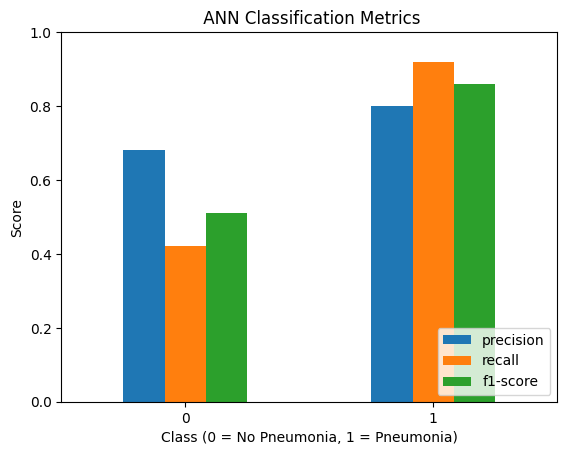

In [231]:
import matplotlib.pyplot as plt


report_ann = classification_report(test_labels, predictions, output_dict=True)

df_report_ann = pd.DataFrame(report_ann).transpose().round(2)


df_report_ann.iloc[0:2, 0:3].plot(kind='bar')

plt.title(" ANN Classification Metrics")
plt.ylabel("Score")
plt.xlabel("Class (0 = No Pneumonia, 1 = Pneumonia)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

### ANN ( Artififcial Neural Network) model overview

The initial Artificial Neural Network (ANN) model showed biased behaviour, achieving 70.4% accuracy but predicting almost all patients as having pneumonia (162 true positives, 63 false positives), with just 3% recall for non-pneumonia cases. This resulted in very poor identification of non-Pneumonia patients and made the model unsuitable for clinical use.
After hyperparameter tuning, performance improved significantly, with accuracy increasing to 78.1% by expanding the hidden layers value from 4 to 24 neurons, allowing the model to capture more complex patterns. The tuned model achieved much better balance, correctly identifying 155 pneumonia cases and 27 healthy patients, with 13 false negatives and 38 false positives. This maintained strong pneumonia recall (92%) while improving non-pneumonia recall to 42%.
From a clinical perspective, this represents a substantial improvement, as the model significantly reduces missed diagnoses while improving identification of healthy patients. Although false positives remain, potentially increasing resource usage, the model provides a strong balance between sensitivity and overall performance.
Overall, the tuned ANN demonstrates the best performance among all models, though its effectiveness depends on careful tuning and continued improvement to reduce remaining errors.

## **7. Ensemble Classification**

#### 1st method =  Hard Voting

In [232]:
# Hard Voting model

import numpy as np

class MyVotingClassifier:

  # The class constructor
  def __init__(self, models):
    # store a copy of the model objects we've been handed
    self.models = models

    # how many were there
    self.n_models = len(models)

  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):

    # what are the unique labels in this problem
    self.labels = np.unique(train_labels)

    # how many are there
    self.n_labels = self.labels.shape[0]

    # loop over the models we've been supplied, and train them on the training data
    for i in range(self.n_models):
      self.models[i].fit(train_examples, train_labels)

  # The method we call to generate predictions for a batch of testing examples (the same as previous labs)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example... (note we're careful to keep it 2D this time, so we can use sklearn models)
        this_example = test_examples[i:i+1,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    #
    labels = np.empty(self.n_models, dtype=self.labels.dtype)

    #
    for i in range(self.n_models):
      labels[i] = self.models[i].predict(this_example)[0]

    #
    unique_labels, counts = np.unique(labels, return_counts=True)
    #
    max_count_index = np.argmax(counts)
    #
    prediction = unique_labels[max_count_index]

    #
    return prediction

In [233]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

# Set the name of the target feature
target_feature = 'Pneumonia'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create one of each of the different models we've met so far
models = [KNeighborsClassifier(), GaussianNB(), DecisionTreeClassifier(random_state=99)]

# Use them to create a voting ensemble
model = MyVotingClassifier(models)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))

Accuracy: 0.6566523605150214 (or 65.7 %)
Confusion Matrix
[[ 46  19]
 [ 61 107]]

Classification Report:
              precision    recall  f1-score   support

           0       0.43      0.71      0.53        65
           1       0.85      0.64      0.73       168

    accuracy                           0.66       233
   macro avg       0.64      0.67      0.63       233
weighted avg       0.73      0.66      0.67       233



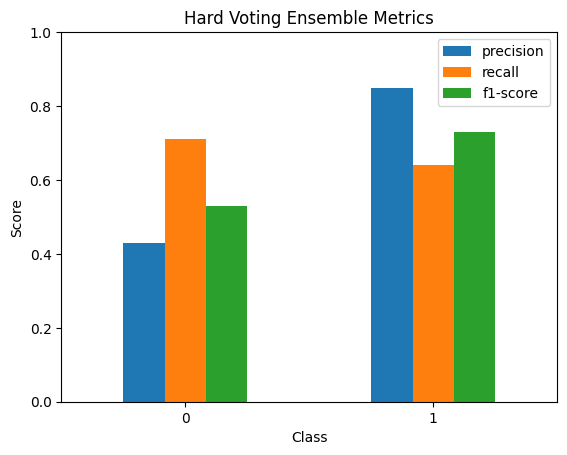

In [234]:
# Visual representation of Hard Voting results through bar graph
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Convert report to DataFrame
report = classification_report(test_labels, predictions, output_dict=True)
df_report = pd.DataFrame(report).transpose().round(2)

# Plot (same style as before)
df_report.iloc[0:2, 0:3].plot(kind='bar')

plt.title("Hard Voting Ensemble Metrics")
plt.ylabel("Score")
plt.xlabel("Class")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()


#### 2nd method = Soft Voting

In [235]:
# Soft Voting model

class MyVotingClassifierV2(MyVotingClassifier):

  # The class constructor
  def __init__(self, models, voting='soft'):
    super().__init__(models)   # call parent constructor

    # store the voting approach (hard/soft)
    self.voting = voting

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    if self.voting == 'hard':
      # the is the same code we used in the original voting class
      labels = np.empty(self.n_models, dtype=self.labels.dtype)

      for i in range(self.n_models):
        labels[i] = self.models[i].predict(this_example)[0]

      unique_labels, counts = np.unique(labels, return_counts=True)
      max_count_index = np.argmax(counts)
      prediction = unique_labels[max_count_index]

    elif self.voting == 'soft':
      #
      probabilities = np.zeros(self.n_labels)

      #
      for i in range(self.n_models):
        probabilities += self.models[i].predict_proba(this_example)[0]

      #
      max_count_index = np.argmax(probabilities)
      #
      prediction = self.labels[max_count_index]

    return prediction

In [236]:
# Set the name of the target feature
target_feature = 'Pneumonia'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create one of each of the different models we've met so far
models = [KNeighborsClassifier(), GaussianNB(), DecisionTreeClassifier(random_state=99)]

# Use them to create a voting ensemble
model = MyVotingClassifierV2(models)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))

Accuracy: 0.6523605150214592 (or 65.2 %)
Confusion Matrix
[[ 46  19]
 [ 62 106]]

Classification Report:
              precision    recall  f1-score   support

           0       0.43      0.71      0.53        65
           1       0.85      0.63      0.72       168

    accuracy                           0.65       233
   macro avg       0.64      0.67      0.63       233
weighted avg       0.73      0.65      0.67       233



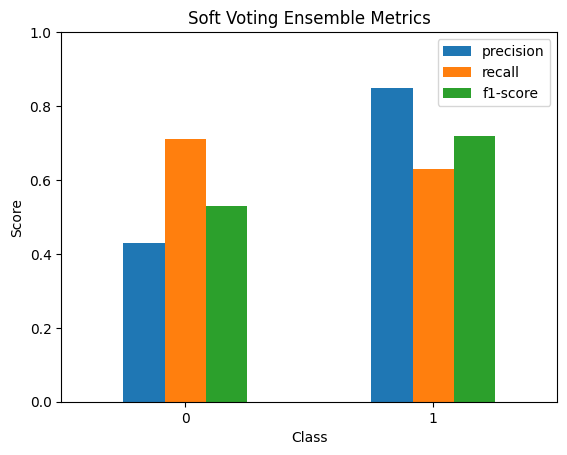

In [237]:
# Visual representation of Soft Voting results through bar graph
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Convert report to DataFrame
report = classification_report(test_labels, predictions, output_dict=True)
df_report = pd.DataFrame(report).transpose().round(2)

# Plot (same style as before)
df_report.iloc[0:2, 0:3].plot(kind='bar')

plt.title("Soft Voting Ensemble Metrics")
plt.ylabel("Score")
plt.xlabel("Class")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()

#### 3rd method = Bagging ( Bootstrap aggregating)

In [238]:
# Bagging / Bootstrap aggregating model

import numpy as np


class MyBaggingClassifier:

  # The class constructor
  def __init__(self, base_model, n_models=5, random_state=None):

    # store a copy of the base model we've been handed
    self.base_model = base_model

    # how many copies are requested
    self.n_models = n_models

    # re-seed the random number generator if a value was supplied:
    self.rng = np.random.default_rng(random_state)

  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):

    # what are the unique labels in this problem
    self.labels = np.unique(train_labels)

    # how many training examples do we have to sample from
    self.n_examples = train_examples.shape[0]

    # how many samples will we draw for each model (note - as long as we're using replacement we only tend to include ~64% of the training data)
    self.n_samples = self.n_examples

    # get ready to store our models (we shouldn't use numpy arrays for this kind of thing - it's for numeric data)
    self.models = []

    # train all the requested models on different samples of the training data
    for i in range(self.n_models):

      # grab a copy of the base model - notice we need a deep copy to avoid lots of references to a single model
      this_model = (self.base_model)

      #
      sample_indices = self.rng.choice(self.n_examples, size=self.n_samples, replace=True)

      #
      this_model.fit(train_examples[sample_indices, :], train_labels[sample_indices])

      #
      self.models.append(this_model)

  # The method we call to generate predictions for a batch of testing examples (the same as previous labs)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example... (note we're careful to keep it 2D this time, so we can use sklearn models)
        this_example = test_examples[i:i+1,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    # the is the same code we used in the original voting class
    labels = np.empty(self.n_models, dtype=self.labels.dtype)

    for i in range(self.n_models):
      labels[i] = self.models[i].predict(this_example)[0]

    unique_labels, counts = np.unique(labels, return_counts=True)
    max_count_index = np.argmax(counts)
    prediction = unique_labels[max_count_index]

    return prediction

In [239]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Set the name of the target feature
target_feature = 'Pneumonia'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# What model will we use in this ensemble
base_model = KNeighborsClassifier();

# Use it to create a bagging ensemble
model = MyBaggingClassifier(base_model, n_models=10, random_state=99)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))

Accuracy: 0.6909871244635193 (or 69.1 %)
Confusion Matrix
[[ 30  35]
 [ 37 131]]

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.46      0.45        65
           1       0.79      0.78      0.78       168

    accuracy                           0.69       233
   macro avg       0.62      0.62      0.62       233
weighted avg       0.69      0.69      0.69       233



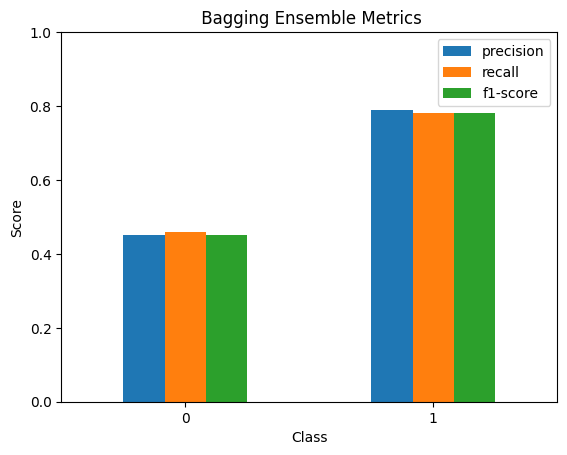

In [240]:
# Visual representation of the Bagging method's results through bar graph
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Convert report to DataFrame
report = classification_report(test_labels, predictions, output_dict=True)
df_report = pd.DataFrame(report).transpose().round(2)

# Plot (same style as before)
df_report.iloc[0:2, 0:3].plot(kind='bar')

plt.title(" Bagging Ensemble Metrics")
plt.ylabel("Score")
plt.xlabel("Class")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()

### Ensemble Classification overview

Ensemble methods (hard voting, soft voting, and bagging) were applied to assess whether combining models improves performance. Hard and soft voting produced similar results, achieving accuracies of 65.7% and 65.2%, while bagging performed slightly better at 69%. Overall, this indicates that combining models did not significantly improve predictive performance.
Differences were observed in classification behaviour. Hard and soft voting were biased towards predicting patients as healthy, achieving higher true negatives (46) and lower false positives (19), but resulting in a high number of false negatives (61–62), indicating many missed pneumonia cases. In contrast, bagging improved pneumonia detection, reducing false negatives to 37 and increasing true positives to 131, but at the cost of higher false positives (35) and weaker identification of healthy patients (30).
This highlights a clear trade-off between sensitivity and specificity. While bagging is more suitable for detecting pneumonia, voting methods may be preferable when minimising unnecessary treatments. Overall, the similar performance across all methods suggests that dataset limitations, particularly overlapping feature patterns, restrict improvements. This demonstrates that increased model complexity does not necessarily lead to better performance.

## **8. K-Means Clustering**




In [241]:
# K-Means Clustering

# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Scale data
scaler = StandardScaler()
X = scaler.fit_transform(observations.drop(columns='Pneumonia'))


# Create a k-means model object (ask for just 1 run, with random cluster centre initialisations, and some debug)
kmeans = KMeans(n_clusters=10, random_state=99, n_init=1, init='random', verbose=1)

# Run the k-means algorithm to look for cluster centres
kmeans.fit(X);

clusters = kmeans.labels_

# Compare clusters to real labels
pd.crosstab(clusters, observations['Pneumonia'])


Initialization complete
Iteration 0, inertia 3956.1948645856796.
Iteration 1, inertia 3188.021743840178.
Iteration 2, inertia 3059.1329232864.
Iteration 3, inertia 2910.0635458414095.
Iteration 4, inertia 2821.5836774265504.
Iteration 5, inertia 2774.8635516975587.
Iteration 6, inertia 2730.9097390174434.
Iteration 7, inertia 2697.214204467917.
Iteration 8, inertia 2689.901840851843.
Iteration 9, inertia 2684.8123772343424.
Iteration 10, inertia 2683.6025322002106.
Iteration 11, inertia 2682.7469132320402.
Iteration 12, inertia 2682.564097151488.
Converged at iteration 12: strict convergence.


Pneumonia,0,1
row_0,,
0,7,38
1,19,92
2,29,58
3,38,56
4,0,37
5,0,7
6,21,38
7,28,37
8,1,19


### K-Means Clustering overview

K-Means clustering showed that the dataset does not naturally separate into pneumonia and non-pneumonia groups. Most clusters contained a mixture of both classes, with examples such as cluster 3 containing 38 healthy and 56 pneumonia cases. While some clusters showed clearer separation, the overall structure was weak, indicating significant overlap in feature patterns. This explains why classification models struggle and highlights the complexity of the dataset.

## **9. Principal components analysis (PCA) for Decision Tree model**

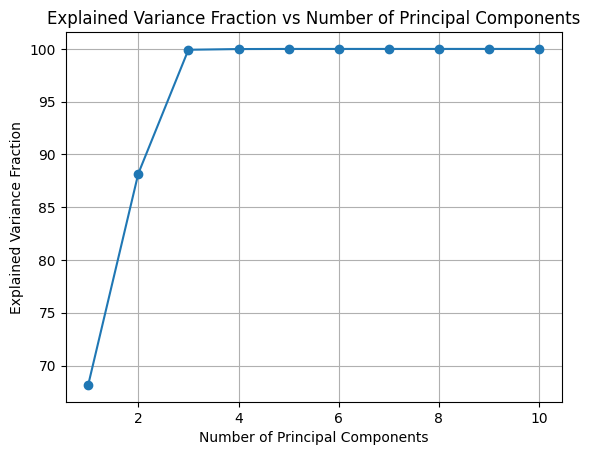

Accuracy: 0.5862068965517241 (or 58.6 %)
Confusion Matrix
[[10 34]
 [26 75]]

Classification Report:
              precision    recall  f1-score   support

           0       0.28      0.23      0.25        44
           1       0.69      0.74      0.71       101

    accuracy                           0.59       145
   macro avg       0.48      0.48      0.48       145
weighted avg       0.56      0.59      0.57       145



In [242]:
# PCA with Decision Tree model

# Importing the packages we use
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

# Set the name of the target feature
target_feature = 'Pneumonia'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.25
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create a PCA model object
pca = PCA()

# Use it to process our training examples
pca.fit(train_examples)

# Plot the cumulative explained variance against the number of PCs
plt.figure()
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_)*100, 'o-')
plt.xlabel('Number of Principal Components')
plt.ylabel('Explained Variance Fraction')
plt.title('Explained Variance Fraction vs Number of Principal Components')
plt.grid(True)
plt.show()

# Let's assume we decide to use the first 2 PCs based on the plot above...

# Create a PCA model object that only retains the first 3 PCs
pca = PCA(n_components= 3)

# Use it to process our training examples
pca.fit(train_examples)

# Transform the original training examples to the new 2D space
train_examples = pca.transform(train_examples)

# Transform the original testing examples to the new 2D space
test_examples = pca.transform(test_examples)

# Create a Decision Tree model object:
model = DecisionTreeClassifier(random_state=99)

# Call the model's fitting algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

# Confusion matrix
print("Confusion Matrix")
print(confusion_matrix(test_labels, predictions))

print("\nClassification Report:")
print(classification_report(test_labels, predictions))

In [243]:
# 3d visualisation of Principal components analysis

import plotly.graph_objects as go
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


X = observations.drop(columns='Pneumonia')

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=3)
pca.fit(X_scaled)

datapoints_pca = pca.transform(X_scaled)


labels = observations['Pneumonia']

fig = go.Figure(data=[
    go.Scatter3d(
        x=datapoints_pca[:, 0],
        y=datapoints_pca[:, 1],
        z=datapoints_pca[:, 2],
        mode='markers',
        marker=dict(
            size=5,
            opacity=0.8,
            color=pd.factorize(labels)[0]
        ),
        text=labels
    )
])

fig.update_layout(
    scene=dict(
        xaxis_title='Principal Component 1',
        yaxis_title='Principal Component 2',
        zaxis_title='Principal Component 3'
    ),
    width=800,
    height=800,
    title='Pneumonia Dataset - PCA (First 3 Components)'
)

fig.show()


#### Hyper-paramater tuning - Principal Components Analysis with Deecision Tree model

PCA Components: 1 → Accuracy: 0.538
PCA Components: 2 → Accuracy: 0.614
PCA Components: 3 → Accuracy: 0.586
PCA Components: 4 → Accuracy: 0.628
PCA Components: 5 → Accuracy: 0.676
PCA Components: 6 → Accuracy: 0.648
PCA Components: 7 → Accuracy: 0.683
PCA Components: 8 → Accuracy: 0.683
PCA Components: 9 → Accuracy: 0.69


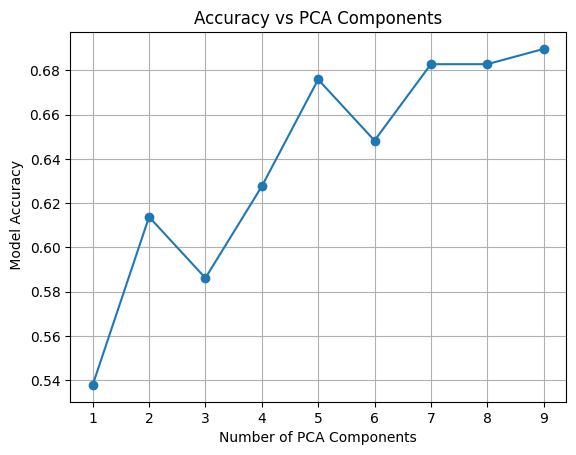

In [244]:
# Testing out different numbers of PCA(n_componenets) to try achieve better accuarcies for the DT model

import matplotlib.pyplot as plt


train_examples = observations_train.drop(columns='Pneumonia').to_numpy()
test_examples  = observations_test.drop(columns='Pneumonia').to_numpy()

components = []
accuracies = []

for n in range(1, 10):

    pca = PCA(n_components=n)
    pca.fit(train_examples)

    train_pca = pca.transform(train_examples)
    test_pca = pca.transform(test_examples)

    model = DecisionTreeClassifier(random_state=99)
    model.fit(train_pca, train_labels)

    predictions = model.predict(test_pca)

    accuracy = sum(predictions == test_labels) / len(test_labels)

    print("PCA Components:", n, "→ Accuracy:", round(accuracy, 3))

    components.append(n)
    accuracies.append(accuracy)

# Line graph to visualise different Decision Tree model accuracies depending on the number of varying PCA(n_components)
plt.figure()
plt.plot(components, accuracies, marker='o')

plt.xlabel("Number of PCA Components")
plt.ylabel(" Model Accuracy")
plt.title("Accuracy vs PCA Components")

plt.grid(True)
plt.show()

In [245]:
# Observing Confusion Matrix of the Decision Tree model when PCA(n_components = 9 ) - This number of n_components showed the highest levels of accuracy as shown in previous graph

from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report

#   PCA components set to 9
pca = PCA(n_components=9)

#  Fit PCA
pca.fit(train_examples)

#  Transform data
train_pca = pca.transform(train_examples)
test_pca = pca.transform(test_examples)

#  Train model
model = DecisionTreeClassifier(random_state=99)
model.fit(train_pca, train_labels)

#  Predict
predictions = model.predict(test_pca)

#  Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, predictions))

#  Classification report
print("\nClassification Report:")
print(classification_report(test_labels, predictions))


Confusion Matrix:
[[22 22]
 [23 78]]

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.50      0.49        44
           1       0.78      0.77      0.78       101

    accuracy                           0.69       145
   macro avg       0.63      0.64      0.64       145
weighted avg       0.69      0.69      0.69       145



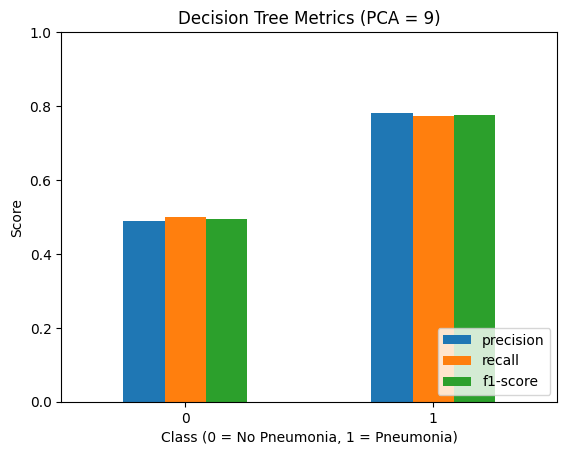

In [246]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Convert classification report to DataFrame
report = classification_report(test_labels, predictions, output_dict=True)
df_report_dt = pd.DataFrame(report).transpose()

# Plot (same style as KNN)
df_report_dt.iloc[0:2, 0:3].plot(kind='bar')

plt.title("Decision Tree Metrics (PCA = 9)")
plt.ylabel("Score")
plt.xlabel("Class (0 = No Pneumonia, 1 = Pneumonia)")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

### Principal Components Analysis (PCA) overview

Principal Component Analysis (PCA) was applied as a dimensionality reduction technique to compress the original features into components capturing the most variance. With 3 components, the model retained nearly all variance but performed poorly, with accuracy dropping to 58.6%, indicating that important diagnostic information was lost despite preserving overall structure. The confusion matrix confirmed weak classification and difficulty distinguishing between pneumonia and healthy cases.
Increasing to 9 components improved accuracy to 69%, with 78 true positives, 22 false positives, 23 false negatives, and 22 true negatives. However, visualisation still showed significant overlap between classes, suggesting that patients share similar feature patterns regardless of diagnosis. This indicates that while PCA captures variance, these patterns do not strongly align with clinical outcomes.
Overall, although performance improved with more components, PCA did not achieve clear class separation. While useful for reducing dimensionality, it must be used carefully in clinical settings, as excessive reduction can remove critical diagnostic information and increase misclassification risk.

# **Conclusions**



### Final Table and Graph to compare performace of all models used

In [247]:
import pandas as pd

# Create the final comparison table
data = {
    "Model": [
        "KNN",
        "Naive Bayes",
        "Decision Tree",
        "Logistic Regression",
        "SVM",
        "ANN (Tuned)",
        "Hard Voting",
        "Soft Voting",
        "Bagging"
    ],

    "Accuracy": [
        0.69,
        0.578,
        0.638,
        0.738,
        0.687,
        0.781,
        0.657,
        0.652,
        0.657
    ],

    "Confusion Matrix (TN, FP / FN, TP)": [
        "TN=14, FP=24 | FN=13, TP=65",
        "TN=35, FP=3 | FN=46, TP=32",
        "TN=20, FP=18 | FN=23, TP=55",
        "TN=41, FP=24 | FN=40, TP=128",
        "TN=25, FP=40 | FN=33, TP=135",
        "TN=27, FP=38 | FN=13, TP=155",
        "TN=46, FP=19 | FN=61, TP=107",
        "TN=46, FP=19 | FN=62, TP=106",
        "TN=28, FP=37 | FN=43, TP=125"
    ],

    "Recall (Pneumonia)": [
        0.83,
        0.41,
        0.71,
        0.76,
        0.80,
        0.92,
        0.64,
        0.63,
        0.74
    ],

    "Recall (Non‑Pneumonia)": [
        0.37,
        0.92,
        0.53,
        0.63,
        0.38,
        0.42,
        0.71,
        0.71,
        0.43
    ],

    "Key Behaviour": [
        "High sensitivity, many false positives",
        "Strong healthy detection, misses pneumonia",
        "Balanced but moderate performance",
        "Stable, interpretable, good balance",
        "Sensitive to tuning, moderate balance",
        "Best overall balance and accuracy",
        "Good healthy detection, many missed cases",
        "Similar to hard voting, no improvement",
        "Improved pneumonia detection, more false positives"
    ]
}

# Create DataFrame
df_final = pd.DataFrame(data)

# Round numerical columns for neatness
df_final["Accuracy"] = df_final["Accuracy"].round(2)
df_final["Recall (Pneumonia)"] = df_final["Recall (Pneumonia)"].round(2)
df_final["Recall (Non‑Pneumonia)"] = df_final["Recall (Non‑Pneumonia)"].round(2)

# Display as a proper table (Jupyter/Colab)
df_final




,Model,Accuracy,"Confusion Matrix (TN, FP / FN, TP)",Recall (Pneumonia),Recall (Non‑Pneumonia),Key Behaviour
0,KNN,0.69,"TN=14, FP=24 | FN=13, TP=65",0.83,0.37,"High sensitivity, many false positives"
1,Naive Bayes,0.58,"TN=35, FP=3 | FN=46, TP=32",0.41,0.92,"Strong healthy detection, misses pneumonia"
2,Decision Tree,0.64,"TN=20, FP=18 | FN=23, TP=55",0.71,0.53,Balanced but moderate performance
3,Logistic Regression,0.74,"TN=41, FP=24 | FN=40, TP=128",0.76,0.63,"Stable, interpretable, good balance"
4,SVM,0.69,"TN=25, FP=40 | FN=33, TP=135",0.80,0.38,"Sensitive to tuning, moderate balance"
5,ANN (Tuned),0.78,"TN=27, FP=38 | FN=13, TP=155",0.92,0.42,Best overall balance and accuracy
6,Hard Voting,0.66,"TN=46, FP=19 | FN=61, TP=107",0.64,0.71,"Good healthy detection, many missed cases"
7,Soft Voting,0.65,"TN=46, FP=19 | FN=62, TP=106",0.63,0.71,"Similar to hard voting, no improvement"
8,Bagging,0.66,"TN=28, FP=37 | FN=43, TP=125",0.74,0.43,"Improved pneumonia detection, more false posit..."


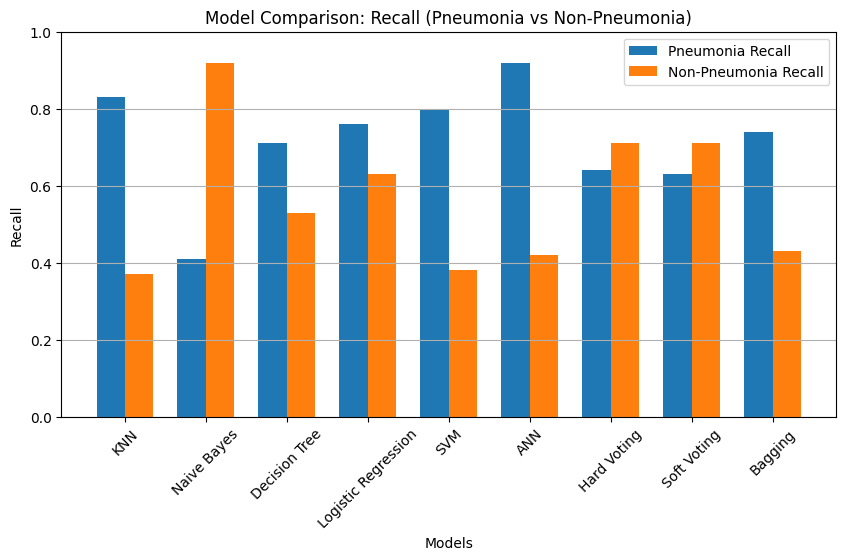

In [248]:
# Bar chart to visually compare the recall values for all models

import matplotlib.pyplot as plt
import numpy as np

# Model names
models = [
    "KNN",
    "Naive Bayes",
    "Decision Tree",
    "Logistic Regression",
    "SVM",
    "ANN",
    "Hard Voting",
    "Soft Voting",
    "Bagging"
]

# Recall values
recall_pneumonia = [0.83, 0.41, 0.71, 0.76, 0.80, 0.92, 0.64, 0.63, 0.74]
recall_non_pneumonia = [0.37, 0.92, 0.53, 0.63, 0.38, 0.42, 0.71, 0.71, 0.43]

# X positions
x = np.arange(len(models))
width = 0.35

# Plot
plt.figure(figsize=(10,5))

plt.bar(x - width/2, recall_pneumonia, width, label="Pneumonia Recall")
plt.bar(x + width/2, recall_non_pneumonia, width, label="Non-Pneumonia Recall")

# Labels
plt.xlabel("Models")
plt.ylabel("Recall")
plt.title("Model Comparison: Recall (Pneumonia vs Non-Pneumonia)")
plt.xticks(x, models, rotation=45)
plt.ylim(0, 1)

plt.legend()
plt.grid(axis='y')

plt.show()

###   Overall Comparison of key Machine Learning models

Among the models evaluated, three key performance patterns emerge: a clearly underperforming model (Naive Bayes), a balanced and reliable model (Logistic Regression), and a high-performing but clinically optimal model (Artificial Neural Network). This indicates that the model is heavily biased towards predicting patients as healthy, resulting in a large number of false negatives (46). Naive Bayes achieved the lowest accuracy (57.8%) and demonstrated poor pneumonia detection with a recall of only 41%, despite achieving a high non-pneumonia recall of 92%. This indicates that the model is heavily biased towards predicting patients as healthy, resulting in a large number of false negatives (46). In a clinical setting, this is unacceptable, as missed pneumonia cases can lead to delayed treatment and serious health risks. In a clinical setting, this is unacceptable, as missed pneumonia cases can lead to delayed treatment and serious health risks. In contrast, Logistic Regression provided a more balanced performance, achieving approximately 73–74% accuracy with a pneumonia recall of 76% and non-pneumonia recall of 63%. This balance makes it a reliable and interpretable model, suitable for practical use where both detection and resource management are important considerations.
The tuned Artificial Neural Network (ANN) achieved the best overall performance, with the highest accuracy (78.1%) and a significantly stronger pneumonia recall of approximately 92%, while maintaining moderate detection of healthy patients (42%). At first glance, this may appear similar to Naive Bayes, which also achieved a recall of 92% for one class. However, the key distinction lies in which class is being prioritised: ANN excels at identifying pneumonia cases, whereas Naive Bayes excels at identifying healthy patients. This difference is critical in a medical context, as failing to detect pneumonia (false negatives) poses a far greater risk than incorrectly diagnosing it (false positives). The ANN model dramatically reduces missed pneumonia cases (FN = 13 compared to 46 for Naive Bayes), making it substantially more clinically reliable.
From a stakeholder perspective, clinicians would strongly favour the ANN model due to its high sensitivity and ability to detect the majority of pneumonia cases, ensuring patient safety and reducing the likelihood of undiagnosed illness. While the ANN produces more false positives, leading to additional testing and operational costs, hospitals and healthcare systems can accommodate these costs more easily than the consequences of missed diagnoses. Overall, although some models demonstrate balanced or specialised performance, the ANN provides the most appropriate trade-off between accuracy and clinical risk, making it the most suitable model for deployment. These findings also highlight that feature overlap within the dataset limits model performance, meaning that prioritising sensitivity remains essential when designing diagnostic systems.

### **Final recommendation on whether a follow-up study should be funded or not**

Overall, based on the analysis conducted throughout this project, I believe that a follow-on study exploring the use of machine learning for pneumonia diagnosis should be funded, as the results demonstrate clear potential to improve diagnostic efficiency and support clinical decision-making, albeit with important limitations.

Across multiple models, performance varied significantly, with the tuned Artificial Neural Network (ANN) achieving the highest accuracy (78.1%) and strongest pneumonia recall (92%). This indicates that the ANN can correctly identify the vast majority of pneumonia cases, significantly reducing the risk of missed diagnoses. From a clinical perspective, this is critical, as false negatives pose a far greater risk than false positives. The ANN reduced false negatives to 13 cases compared to 46 in Naive Bayes, demonstrating a substantial improvement in diagnostic safety.

However, no model achieved near-perfect classification, and a clear trade-off remains between detecting pneumonia and avoiding false positives. While the ANN performs strongly in diagnosis, it still misclassifies a notable number of healthy patients, potentially leading to increased testing and resource pressure. This highlights a key limitation: these models are not yet reliable enough to fully replace trained medical professionals.

From a stakeholder perspective, clinicians would value the ANN’s high sensitivity, ensuring fewer missed cases, while hospital managers may accept higher costs from false positives in exchange for improved patient safety and faster initial assessments. Patients may benefit from quicker screening but would still require confirmation from medical professionals. Additionally, PCA and clustering analysis revealed significant overlap between pneumonia and healthy cases, suggesting that current features do not fully separate the classes, limiting model performance.

While eliminating errors entirely is unlikely in the near future, I believe further improvements are achievable through the help of funding as this could help retrieve better/ more insightful data,  develop more refined models, and continue deeper research. In conclusion, I recommend that the follow-on study should be funded, with the understanding that machine learning should be developed as a clinical support tool rather than a replacement for medical expertise, therefore ensuring a safe, efficient, and trustworthy Pneumonia diagnostic processes.

# **References**

1.   Evaluation of Machine Learning Methods Developed for Prediction and Diagnosis of Pneumonia: A Systematic Review (n.d.) National Center for Biotechnology Information. Available at: https://pmc.ncbi.nlm.nih.gov/articles/PMC12665151/ (Accessed:  24th April 2026).

2.   Weekly colabs - week 1- 11
3.   Weekly research






